# 01 · Spline transformations

**qlPCA — quasi-linear PCA.** This notebook covers section 1.1 of the PhD thesis
[`lavado2012phd`] (earlier account: MSc thesis, chapter 4 [`lavado2004msc`]).
It introduces the family of transformations that qlPCA fits to each continuous
variable: *splines of low degree* $v$ with $r$ interior knots, written in the basis of
**I-splines**, and the **pseudo-indicator matrix** that collects the basis functions
evaluated at the data.

Everything computed here uses the package (`qlpca.splines`); nothing is re-implemented in the notebook.

*Contents:* 1. splines, knots and bases · 2. thesis Figure 1.1 · 3. B-splines and I-splines of degree 0–3 ·
4. why I-splines, and where the constant went · 5. the pseudo-indicator matrix of thesis section 3.1.1 ·
6. monotone splines · References.

In [1]:
import json, pathlib
import numpy as np
import matplotlib.pyplot as plt
from qlpca import bspline_basis, ispline_basis, pseudo_indicator
from qlpca.splines import knot_sequence, interior_knots
from qlpca.plots import set_style, BLUE, ORANGE, INK, INK2, GRID

set_style()
np.set_printoptions(precision=2, suppress=True, linewidth=110)

## 1 · Splines, knots and bases

A **spline of degree $v$ with $r$ interior knots** is a function that is a polynomial of degree $v$
on each of the $r+1$ intervals between the knots and joins smoothly at the knots (continuous up to
the derivative of order $v-1$) [`deboor1978practical`, `schumaker1981spline`]. Such functions form a
vector space of dimension $v+r+1$. The two extreme cases that matter for the Gifi family of methods are

| class of transformations | degree $v$ | interior knots $r$ | method |
|---|---|---|---|
| linear | 1 | 0 | ordinary PCA |
| piecewise constant | 0 | maximal (one per gap between categories) | HOMALS / MCA |
| **piecewise linear** | **1** | **small (1, 2, 3)** | **qlPCA** |

(See notebook 02 for the loss function behind this table.)

**Knots.** In the thesis and in this package the interior knots of every variable sit at the percentiles
$\mathrm{round}(100\,i/(r+1))$, $i=1,\dots,r$, of the (standardised) variable, so that each sub-interval holds
roughly the same number of observations: $r=1\to 50$; $r=2\to 33, 67$; $r=3\to 25,50,75$. Percentiles follow
MATLAB's `prctile` (Hazen definition), not numpy's default — the two give different knots.
The *knot sequence* repeats the minimum and the maximum $v+1$ times each.

**Bases.** Three bases of the same space appear in the thesis:

* **B-splines** $B_1,\dots,B_{v+r+1}$ (non-negative, summing to one at every $x$);
* **M-splines** $M_i = \frac{v+1}{t_{i+v+1}-t_i}\,B_i$ (each integrates to one) — the recursion coded in
  the MATLAB listings `create_mspline.m`;
* **I-splines** $I_i(x)=\int_{\min}^{x} M_i$ — the cumulative versions, $I_i=\sum_{q>i}B_q$ (the thesis
  formula $I_i(x)=\sum_{q=i+1}^{j}\frac{t_{q+v+1}-t_q}{v+1}M_q(x)$). There are $w=v+r$ of them [`ramsay1988monotone`].

A spline transformation of variable $j$ is then $f_j = G_j\,y_j$, where $G_j$ ($n\times w$) holds the
basis functions evaluated at $h_j$ — the *pseudo-indicator matrix* — and $y_j$ are the coefficients.

## 2 · Thesis Figure 1.1

Figure 1.1 of the thesis shows the two I-splines of degree 1 with one interior knot at the median,
$I_1, I_2$ (thick and thin lines), and the spline $f = 1.2\,I_1+0.6\,I_2$ with its images of the data (stars).
The text gives $I_1(0.58)=1$, $I_2(0.58)=0.29$ and $f(0.58)=1.37$. Those three numbers fix the median:
$I_2(0.58)=(0.58-m_2)/(1-m_2)=0.29\Rightarrow m_2\approx0.4085$ (min $=0$, max $=1$). With that knot the figure is
regenerated below, and the printed numbers are checked.

I1(0.58) = 1.00, I2(0.58) = 0.29, f(0.58) = 1.37   (thesis: 1, 0.29, 1.37)


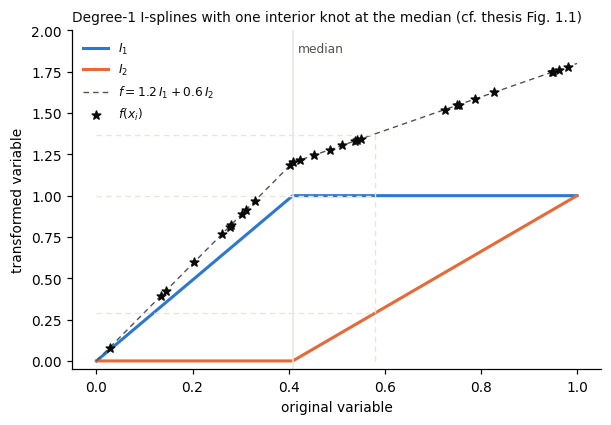

In [2]:
m1, m2, m3 = 0.0, 0.4085, 1.0
knots = np.array([m1, m1, m2, m3, m3])               # degree 1: min x2, one interior knot, max x2
coef = np.array([1.2, 0.6])

grid = np.linspace(0, 1, 401)
I = ispline_basis(grid, 1, knots)
f = I @ coef

rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 1, 28))
fx = ispline_basis(x, 1, knots) @ coef

I58 = ispline_basis(np.array([0.58]), 1, knots)[0]
print(f"I1(0.58) = {I58[0]:.2f}, I2(0.58) = {I58[1]:.2f}, f(0.58) = {I58 @ coef:.2f}   (thesis: 1, 0.29, 1.37)")

fig, ax = plt.subplots(figsize=(6.2, 4.0))
ax.plot(grid, I[:, 0], color=BLUE, lw=2.0, label=r"$I_1$")
ax.plot(grid, I[:, 1], color=ORANGE, lw=2.0, label=r"$I_2$")
ax.plot(grid, f, color=INK2, lw=0.9, ls=(0, (4, 3)), label=r"$f=1.2\,I_1+0.6\,I_2$")
ax.scatter(x, fx, marker="*", s=34, color=INK, zorder=4, label=r"$f(x_i)$")
ax.axvline(m2, color=GRID, lw=1); ax.text(m2 + 0.01, 1.93, "median", ha="left", va="top", fontsize=8, color=INK2)
for yy in (1.0, 0.29, 1.37):
    ax.hlines(yy, 0, 0.58, color=GRID, lw=0.9, ls=(0, (4, 3)))
ax.vlines(0.58, 0, 1.37, color=GRID, lw=0.9, ls=(0, (4, 3)))
ax.set_xlabel("original variable"); ax.set_ylabel("transformed variable")
ax.set_ylim(-0.05, 2); ax.legend(loc="upper left", fontsize=8)
ax.set_title("Degree-1 I-splines with one interior knot at the median (cf. thesis Fig. 1.1)", loc="left", fontsize=9)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.show()

$f$ is piecewise linear and *not* constant on any interval. The qlPCA algorithm does not fix the coefficients
$(1.2, 0.6)$: it chooses them by a multiple regression of $Xa_j$ on the columns of $G_j$, so that **all** the data,
not just two points per segment, determine the fitted transformation.

## 3 · B-splines and I-splines of degree 0–3

The same knots, different degrees. Degree 0 gives the piecewise-constant step functions behind the indicator matrix of
categorical data (notebook 03); degree 1 gives the broken lines of qlPCA; higher degrees are smoother.
The package computes B-splines with scipy and obtains I-splines by a reverse cumulative sum, which reproduces the
recursion of the MATLAB listing (checked against the prototype in notebook 04).

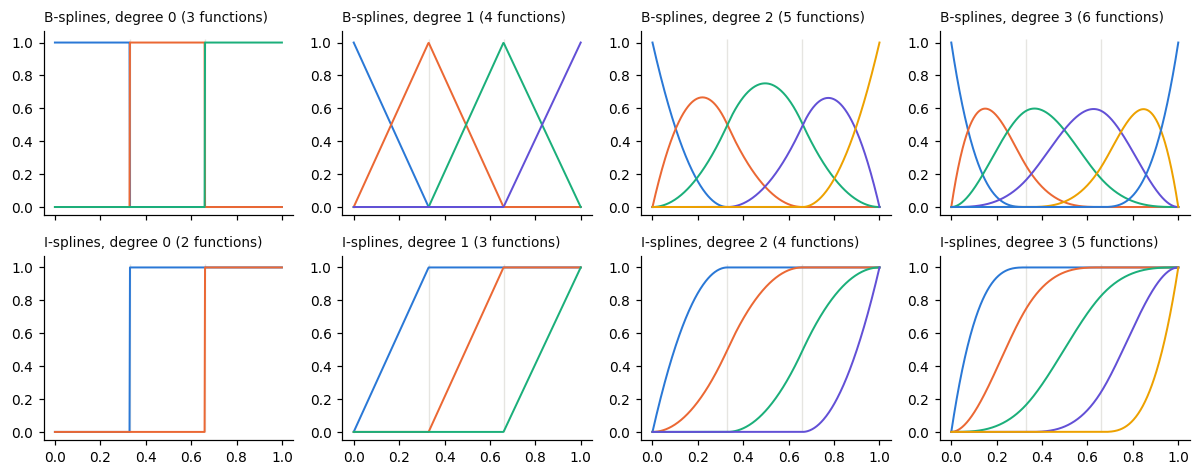

In [3]:
x = np.linspace(0, 1, 500)
interior = np.array([0.33, 0.66])                      # two interior knots, as in thesis section 3.1.1
fig, axes = plt.subplots(2, 4, figsize=(11, 4.4), sharex=True)
colors = [BLUE, ORANGE, "#1baf7a", "#6250d6", "#eda100"]
for v in range(4):
    t = np.r_[[0.0] * (v + 1), interior, [1.0] * (v + 1)]
    B = bspline_basis(x, v, t)
    Ii = ispline_basis(x, v, t)
    for i in range(B.shape[1]):
        axes[0, v].plot(x, B[:, i], color=colors[i % 5], lw=1.3)
    for i in range(Ii.shape[1]):
        axes[1, v].plot(x, Ii[:, i], color=colors[i % 5], lw=1.3)
    axes[0, v].set_title(f"B-splines, degree {v} ({B.shape[1]} functions)", fontsize=9, loc="left")
    axes[1, v].set_title(f"I-splines, degree {v} ({Ii.shape[1]} functions)", fontsize=9, loc="left")
    for r_ in (0, 1):
        axes[r_, v].vlines(interior, 0, 1.02, color=GRID, lw=0.9, zorder=0)
        for s in ("top", "right"): axes[r_, v].spines[s].set_visible(False)
plt.tight_layout(); plt.show()

Two facts to read off the figure: the B-splines of every degree sum to one at each $x$; the I-splines are
non-decreasing, start at 0 and reach 1 at the right end. With $r$ interior knots there are $v+r+1$ B-splines
but only $w=v+r$ I-splines.

## 4 · Why I-splines, and where the constant went

The first B-spline is dropped when building the I-splines, so the **constant function is not in their span**.
This is deliberate in the thesis's formulation (the I-splines are the building blocks of *monotone* transformations,
section 6), and it has a consequence that matters for the algorithm: the regression in step II of the algorithm needs an
intercept, which the MATLAB code supplies by standardising the columns of $G$ and which the printed pseudo-code omits.
Notebook 04 shows how much that matters. The cell below checks the linear-algebra fact itself, on thesis-like data.

In [4]:
X0 = np.random.default_rng(0).normal(size=40)
t = knot_sequence(X0, 1, 2)
B = bspline_basis(X0, 1, t)
Ii = ispline_basis(X0, 1, t)
ones = np.ones((len(X0), 1))
rank = lambda M: np.linalg.matrix_rank(M, tol=1e-10)
print("B-splines  (v+r+1 columns): rank", rank(B), " contains constant:", rank(np.c_[B, ones]) == rank(B))
print("I-splines  (v+r   columns): rank", rank(Ii), " contains constant:", rank(np.c_[Ii, ones]) == rank(Ii))
print("[1, I-splines]            : rank", rank(np.c_[ones, Ii]), " = rank of B-splines:", rank(np.c_[ones, Ii]) == rank(B))
print("B-splines sum to one:", np.allclose(B.sum(1), 1))

B-splines  (v+r+1 columns): rank 4  contains constant: True
I-splines  (v+r   columns): rank 3  contains constant: False
[1, I-splines]            : rank 4  = rank of B-splines: True
B-splines sum to one: True


So *constant + I-splines* spans exactly the same space as the full B-spline basis. The default estimator of this
package uses the full B-spline basis, centred (docs/DESIGN.md, D2); `legacy=True` uses the standardised I-splines of the
MATLAB code. They give the same fitted values.

## 5 · The pseudo-indicator matrix of thesis section 3.1.1

For a categorical variable the **indicator matrix** has one 0/1 column per category. The thesis generalises it: the
*pseudo-indicator matrix* has one column per basis function. Section 3.1.1 illustrates this with eight values of a variable
(its Table 3.1), the B-spline matrix of degree 1 with two interior knots at the 33rd and 66th percentiles, and the I-spline matrix
of degree 2 with the same knots. The cell below computes both with the package and compares them with the printed matrices.

**This comparison does not reproduce the thesis**, and it is not used as a test target. The printed rows are close to
the computed ones but never equal to two decimals (differences up to about 0.2), and the discrepancy is largest at the extremes:
the smallest value $h=1.72$ gets $(1,0,0,0)$ here but $(0.81,0.19,0,0)$ in the thesis, which would require a first knot
*below* the minimum. The printed matrices were therefore probably produced with other boundary knots (outside $[\min,\max]$)
than the code printed in the thesis uses. This is open question 3 for the author (docs/SPEC.md §9).

In [5]:
ref = json.load(open(pathlib.Path("..") / "tests" / "reference_values.json", encoding="utf8"))["pseudo_indicator_example"]
h = np.array(ref["h"])
k1 = knot_sequence(h, 1, 2)
B1 = bspline_basis(h, 1, k1)
thesis_B = np.array(ref["bspline_degree1_2knots"])
print("interior knots (percentiles 33, 67 by MATLAB round):", interior_knots(h, 2))
print("\nB-splines, degree 1, 2 interior knots: package | thesis (printed)")
for a, b, hv in zip(B1, thesis_B, h):
    print(f"  h={hv:4.2f}  {a}  |  {b}   {'match' if np.allclose(a, b, atol=0.006) else ''}")

I2, k2 = pseudo_indicator(h, 2, 2)
thesis_I = np.array(ref["ispline_degree2_2knots_as_printed"])
o = np.argsort(h, kind="stable")
print("\nI-splines, degree 2, 2 interior knots (rows sorted by h): package | thesis (printed)")
for a, b in zip(I2[o], thesis_I):
    print(f"  {a}  |  {b}   {'match' if np.allclose(a, b, atol=0.006) else ''}")
print("\nrow sums of the I-spline matrix are not 1 (unlike B-splines), as the thesis notes:", I2.sum(1).round(2))

interior knots (percentiles 33, 67 by MATLAB round): [1.74 1.76]

B-splines, degree 1, 2 interior knots: package | thesis (printed)
  h=1.75  [0.  0.5 0.5 0. ]  |  [0.   0.48 0.52 0.  ]   
  h=1.76  [0.   0.   0.97 0.03]  |  [0.   0.   0.96 0.04]   
  h=1.80  [0.   0.   0.19 0.81]  |  [0.   0.   0.26 0.74]   
  h=1.73  [0.53 0.47 0.   0.  ]  |  [0.43 0.57 0.   0.  ]   
  h=1.75  [0.  0.5 0.5 0. ]  |  [0.   0.48 0.52 0.  ]   
  h=1.74  [0.07 0.93 0.   0.  ]  |  [0.05 0.95 0.   0.  ]   
  h=1.81  [0. 0. 0. 1.]  |  [0.   0.   0.09 0.91]   
  h=1.72  [1. 0. 0. 0.]  |  [0.81 0.19 0.   0.  ]   

I-splines, degree 2, 2 interior knots (rows sorted by h): package | thesis (printed)
  [0. 0. 0. 0.]  |  [0.31 0.02 0.   0.  ]   
  [0.72 0.12 0.   0.  ]  |  [0.75 0.15 0.   0.  ]   
  [1.   0.48 0.   0.  ]  |  [0.97 0.42 0.   0.  ]   
  [1.   0.89 0.06 0.  ]  |  [1.   0.78 0.02 0.  ]   
  [1.   0.89 0.06 0.  ]  |  [1.   0.78 0.02 0.  ]   
  [1.   1.   0.29 0.  ]  |  [1.   0.98 0.17 0.  ]   
  [1.   

## 6 · Monotone splines

Because every I-spline is non-decreasing, **a non-negative combination of I-splines plus a constant is a non-decreasing
function**; conversely every non-decreasing spline of that degree and knots has that form [`ramsay1988monotone`, `winsberg1983monotone`].
Restricting the coefficients to $y_j\ge 0$ therefore gives *monotone* (ordinal-like) transformations. The package offers this as
`QLPCA(monotone=True)` (docs/DESIGN.md, D5); notebooks 04 and 06 use it. The unrestricted fit is the qlPCA of the thesis.

In [6]:
c = np.array([0.8, 0.0, 1.5])                          # non-negative coefficients
xg = np.linspace(0, 1, 300)
f1 = ispline_basis(xg, 1, np.array([0, 0, 0.33, 0.66, 1, 1.0])) @ c
print("non-decreasing:", bool(np.all(np.diff(f1) >= -1e-12)), "| flat stretch where the coefficient is 0:",
      bool(np.any(np.abs(np.diff(f1)) < 1e-12)))

non-decreasing: True | flat stretch where the coefficient is 0: True


A zero coefficient makes the transformation **flat** between two knots; observations on such a plateau all receive the same
transformed value and cannot be told apart afterwards (this is why reconstruction with `monotone=True` is not exact on plateaus).

## References

* `lavado2012phd` — N. Lavado, *Extensões via splines da Análise em Componentes Principais*, PhD thesis, ISCTE-IUL, 2012. §1.1, §3.1.1.
* `lavado2004msc` — N. Lavado, *Análise em Componentes Principais Não-Linear*, MSc thesis, ISEGI-UNL, 2004.
* `deboor1978practical` — C. de Boor, *A Practical Guide to Splines*, Springer, 1978.
* `schumaker1981spline` — L. Schumaker, *Spline Functions: Basic Theory*, Wiley, 1981.
* `ramsay1988monotone` — J. O. Ramsay, Monotone regression splines in action, *Statistical Science* 3, 1988.
* `winsberg1983monotone` — S. Winsberg & J. Ramsay, Monotone spline transformations for dimension reduction, *Psychometrika* 48, 1983.